# A discrete Artificial Bee Colony algorithm for the 0-1 knapsack problem

Implementation and evaluation of the binary ABC algorithm of Sabet, Farokhi and Shokouhifar (2012), *A Novel Artificial Bee Colony Algorithm for the Knapsack Problem*.

**Problem.** Given $N$ items with weights $w_i$ and values $v_i$ and a capacity $C$:
$$\max \sum_{i=1}^{N} v_i x_i \quad \text{s.t.} \quad \sum_{i=1}^{N} w_i x_i \le C, \quad x_i \in \{0,1\}.$$

**Method.** Each food source is a binary vector (one bit per item).

1. *Greedy initialisation*: items are packed in decreasing order of $v_i/w_i$ while they fit.
2. *Onlooker selection*: an onlooker picks employed bee $k$ with probability proportional to $Ch_k = \left(F_k / \sum_i F_i\right)^{\mu}$, $\mu \gg 1$.
3. *Recruitment*: the selected bee receives $S_k = \beta\, Ch_k / H + \gamma$ soldiers ($\beta<0$, $\gamma>0$), i.e. neighbourhood trials.
4. *Neighbourhood search*: every bit is flipped with probability $p_{change} = p_{min} + \frac{t}{t_{max}}(p_{max}-p_{min})$; infeasible solutions are repaired by removing the packed items with the lowest ratio $v_i/w_i$. A trial replaces the bee only if it is strictly better.

The implementation is in `src/bee_knapsack/abc.py`; this notebook runs the experiments.

In [1]:
import sys
from pathlib import Path

# Allow running the notebook without `pip install -e .`
sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bee_knapsack import (P08, PISINGER, ArtificialBeeColony, load_pisinger, read_pisinger,
                          run_repeated, sensitivity, convergence_runs, plot_convergence)
from bee_knapsack.instances import DATA_DIR

## 1. Parameters

We use the parameters of Sabet et al. (2012):

| Parameter | Value |
|---|---|
| Employed bees | 50 |
| Onlooker bees | 50 |
| Elite bees $H$ | 5 |
| $\mu$, $\beta$, $\gamma$ | 3, −10, 16 |
| $p_{min}$, $p_{max}$ | 0.04, 0.12 |
| Iterations | 100 |

## 2. Test instances

Pisinger instances with 100, 200 and 500 items and three levels of correlation between values and weights (1 = uncorrelated, 2 = weakly correlated, 3 = strongly correlated), plus P08 (24 items). The optimal solutions of all instances are sparse: only a small fraction of the items is packed. The optima were verified by dynamic programming.

In [2]:
pd.DataFrame([{"instance": name, "file": stem, "capacity": cap, "optimum": opt}
              for name, (stem, cap, opt) in PISINGER.items()])

,instance,file,capacity,optimum
0,PI_1_100,knapPI_1_100_1000_1,1000,9147
1,PI_1_200,knapPI_1_200_1000_1,1000,11238
2,PI_1_500,knapPI_1_500_1000_1,2543,28857
3,PI_2_100,knapPI_2_100_1000_1,995,1514
4,PI_2_200,knapPI_2_200_1000_1,1008,1634
5,PI_2_500,knapPI_2_500_1000_1,2543,4566
6,PI_3_100,knapPI_3_100_1000_1,997,2397
7,PI_3_200,knapPI_3_200_1000_1,997,2697
8,PI_3_500,knapPI_3_500_1000_1,2517,7117
9,PI_1_10000,knapPI_1_10000_1000_1,49877,563647


## 3. A single run per instance

One run per instance with a fixed seed, comparing the solution found with the reference solution shipped with each data file.

In [3]:
rows = []
for name in [n for n in PISINGER if n != "PI_1_10000"]:
    inst = load_pisinger(name)
    abc = ArtificialBeeColony(inst.weights, inst.values, inst.capacity, seed=1)
    solution, profit = abc.optimize()
    _, _, reference = read_pisinger(DATA_DIR / f"{PISINGER[name][0]}.txt")
    rows.append({"instance": name, "profit": profit, "optimum": inst.optimum,
                 "items packed": int(solution.sum()), "items in reference": sum(reference),
                 "same items as reference": bool(np.array_equal(solution, np.array(reference, bool)))})
pd.DataFrame(rows)

,instance,profit,optimum,items packed,items in reference,same items as reference
0,PI_1_100,9147.0,9147,12,12,True
1,PI_1_200,11238.0,11238,16,16,True
2,PI_1_500,28857.0,28857,42,42,True
3,PI_2_100,1513.0,1514,8,9,False
4,PI_2_200,1634.0,1634,9,9,True
5,PI_2_500,4566.0,4566,28,28,True
6,PI_3_100,2397.0,2397,14,14,True
7,PI_3_200,2697.0,2697,17,17,False
8,PI_3_500,7117.0,7117,46,46,False


Whenever the profit equals the optimum but the packed items differ from the reference, the algorithm has found an **alternative optimal solution**: a different subset with the same total value. On PI_3_200, for instance, a different set of items reaches the optimum of 2697, also using the full capacity of 997.

## 4. Repeated runs

The algorithm is stochastic, so we repeat every instance 10 times and report the fraction of runs that reached the optimum (*hit rate*) and the mean runtime.

In [4]:
names = ["PI_1_100", "PI_1_200", "PI_1_500", "PI_2_100", "PI_2_200", "PI_2_500",
         "PI_3_100", "PI_3_200", "PI_3_500"]
bench = pd.DataFrame([run_repeated(inst, runs=10) for inst in [P08] + [load_pisinger(n) for n in names]])
bench.round({"mean": 1, "gap_%": 4, "time_s": 2})

,instance,n,optimum,best,mean,time_s,hit_rate,gap_%
0,P08,24,13549094,13549094.0,13549094.0,0.58,1.0,0.0000
1,PI_1_100,100,9147,9147.0,9147.0,0.92,1.0,0.0000
2,PI_1_200,200,11238,11238.0,11238.0,1.27,1.0,0.0000
3,PI_1_500,500,28857,28857.0,28850.1,1.65,0.7,0.0239
4,PI_2_100,100,1514,1514.0,1513.1,0.95,0.2,0.0594
5,PI_2_200,200,1634,1634.0,1634.0,1.25,1.0,0.0000
6,PI_2_500,500,4566,4566.0,4566.0,1.82,1.0,0.0000
7,PI_3_100,100,2397,2397.0,2397.0,0.92,1.0,0.0000
8,PI_3_200,200,2697,2697.0,2697.0,1.18,1.0,0.0000
9,PI_3_500,500,7117,7117.0,7117.0,1.77,1.0,0.0000


The optimum is reached in every run on 8 of the 10 instances. On PI_1_500 and PI_2_100 some runs end one or a few units below the optimum, with a mean gap well below 0.1 %.

## 5. Convergence

Ten runs on PI_2_500. All runs start from the same greedy solution (4552), which is already within 0.3 % of the optimum, and the neighbourhood search closes the remaining gap.

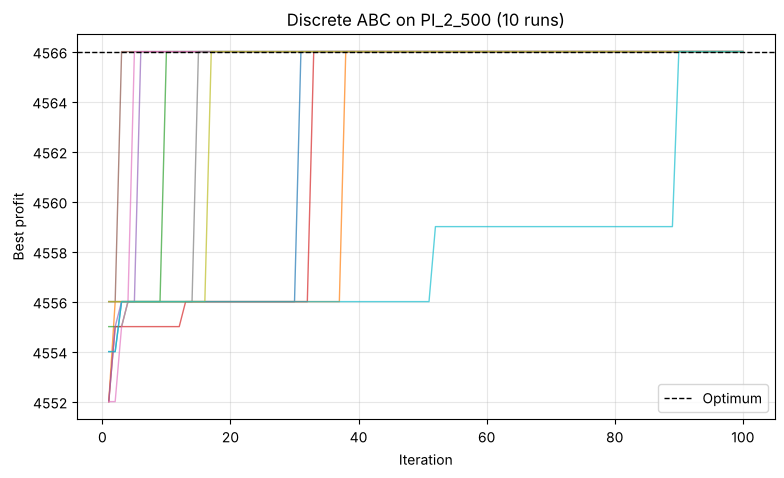

In [5]:
inst = load_pisinger("PI_2_500")
curves = convergence_runs(inst, runs=10)
plot_convergence(curves, optimum=inst.optimum, title="Discrete ABC on PI_2_500 (10 runs)")
plt.show()

## 6. Sensitivity to the colony sizes

Each value is evaluated over 5 runs on PI_2_100, the hardest of the small instances.

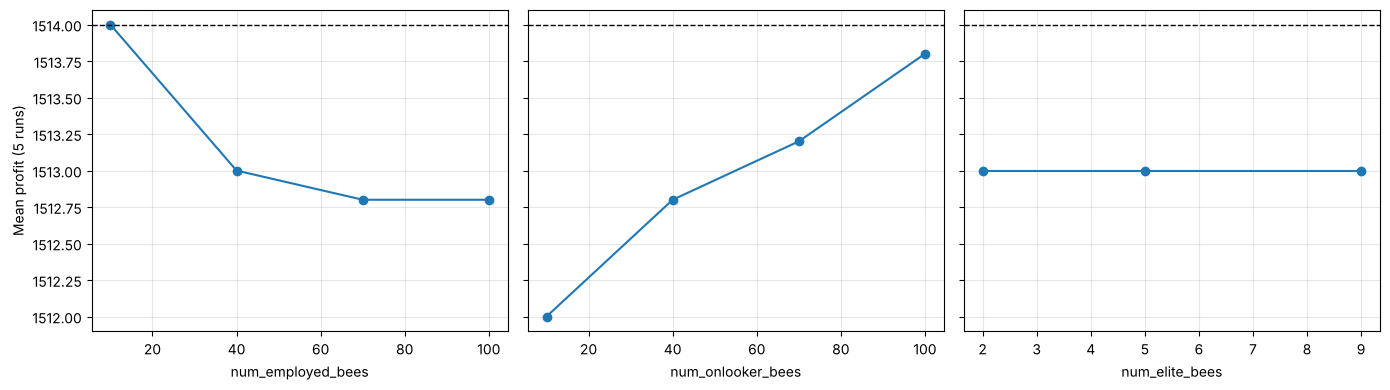

In [6]:
inst = load_pisinger("PI_2_100")
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (param, values) in zip(axes, {"num_employed_bees": range(10, 101, 30),
                                      "num_onlooker_bees": range(10, 101, 30),
                                      "num_elite_bees": [2, 5, 9]}.items()):
    rows = sensitivity(inst, param, values, runs=5)
    ax.plot([r[param] for r in rows], [r["mean"] for r in rows], marker="o")
    ax.axhline(inst.optimum, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel(param); ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Mean profit (5 runs)")
plt.tight_layout(); plt.show()

* **Onlooker bees** have the largest effect: every onlooker triggers about 15 neighbourhood trials, so more onlookers mean more search effort per iteration (and proportionally more runtime).
* **Employed bees**: fewer food sources concentrate the onlookers on the best ones, which tends to help on this instance (with 5 runs per value the effect is small).
* **Elite bees $H$** have no effect. With 50 employed bees, $Ch_k \approx (1/50)^3 \approx 10^{-5}$, so $\beta\, Ch_k/H$ is negligible and every selected bee receives $\lfloor\gamma - \varepsilon\rfloor = 15$ soldiers regardless of $H$. With these parameters the recruitment step is effectively constant.

## 7. A large instance

PI_1_10000 has 10 000 items (capacity 49 877, optimum 563 647).

In [7]:
inst = load_pisinger("PI_1_10000")
abc = ArtificialBeeColony(inst.weights, inst.values, inst.capacity, seed=0)
_, profit = abc.optimize()
print(f"profit = {profit:,.0f}  (optimum {inst.optimum:,}, gap {100 * (inst.optimum - profit) / inst.optimum:.4f} %)")

profit = 563,605  (optimum 563,647, gap 0.0075 %)


The result equals the value of the greedy initial solution (563 605): on this instance the neighbourhood search never finds an improvement. With 10 000 items, a flip probability of 4–12 % changes 400–1 200 bits at once, and after the repair step such a trial is practically never better than the current solution. The gap of 42 units (0.0075 %) is therefore the gap of the greedy heuristic itself. A flip probability that scales with the instance size (e.g. a few bits per trial instead of a fixed percentage) is a natural next step.

## References

* S. Sabet, F. Farokhi, M. Shokouhifar (2012). *A Novel Artificial Bee Colony Algorithm for the Knapsack Problem.* IEEE.
* D. Pisinger. Instances of the 0/1 knapsack problem (knapPI).
* J. Burkardt. KNAPSACK_01: data for the 01 knapsack problem (P08).